### Car Fuel Efficiency Prediction Using Polynomial Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [118]:
df = pd.read_csv('auto-mpg.csv')

In [119]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [120]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


In [121]:
origin_map = {1:'USA',2:'Europe',3:'Asia'}
df['origin'] = df['origin'].map(origin_map)

In [122]:
df = pd.get_dummies(df,columns=['origin'],drop_first=True,dtype=int)

In [123]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,car name,origin_Europe,origin_USA
0,18.0,8,307.0,130,3504,12.0,70,chevrolet chevelle malibu,0,1
1,15.0,8,350.0,165,3693,11.5,70,buick skylark 320,0,1
2,18.0,8,318.0,150,3436,11.0,70,plymouth satellite,0,1
3,16.0,8,304.0,150,3433,12.0,70,amc rebel sst,0,1
4,17.0,8,302.0,140,3449,10.5,70,ford torino,0,1


In [124]:
#convert all to numerical features and remove the unnecessary features
df['horsepower'] = pd.to_numeric(df['horsepower'],errors='coerce')

In [125]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

In [126]:
df.isnull().sum()

mpg              0
cylinders        0
displacement     0
horsepower       0
weight           0
acceleration     0
model year       0
car name         0
origin_Europe    0
origin_USA       0
dtype: int64

In [127]:
df.drop(columns=['car name'],inplace=True)

In [128]:
corr = df.corr()
corr

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_Europe,origin_USA
mpg,1.000000,-0.775396,-0.804203,-0.771437,-0.831741,0.420289,0.579267,0.259022,-0.568192
cylinders,-0.775396,1.000000,0.950721,0.838939,0.896017,-0.505419,-0.348746,-0.352861,0.604351
displacement,-0.804203,0.950721,1.000000,0.893646,0.932824,-0.543684,-0.370164,-0.373886,0.651407
horsepower,-0.771437,0.838939,0.893646,1.000000,0.860574,-0.684259,-0.411651,-0.281258,0.486083
weight,-0.831741,0.896017,0.932824,0.860574,1.000000,-0.417457,-0.306564,-0.298843,0.598398
acceleration,0.420289,-0.505419,-0.543684,-0.684259,-0.417457,1.000000,0.288137,0.204473,-0.250806
model year,0.579267,-0.348746,-0.370164,-0.411651,-0.306564,0.288137,1.000000,-0.024489,-0.139883
origin_Europe,0.259022,-0.352861,-0.373886,-0.281258,-0.298843,0.204473,-0.024489,1.000000,-0.597198
origin_USA,-0.568192,0.604351,0.651407,0.486083,0.598398,-0.250806,-0.139883,-0.597198,1.000000


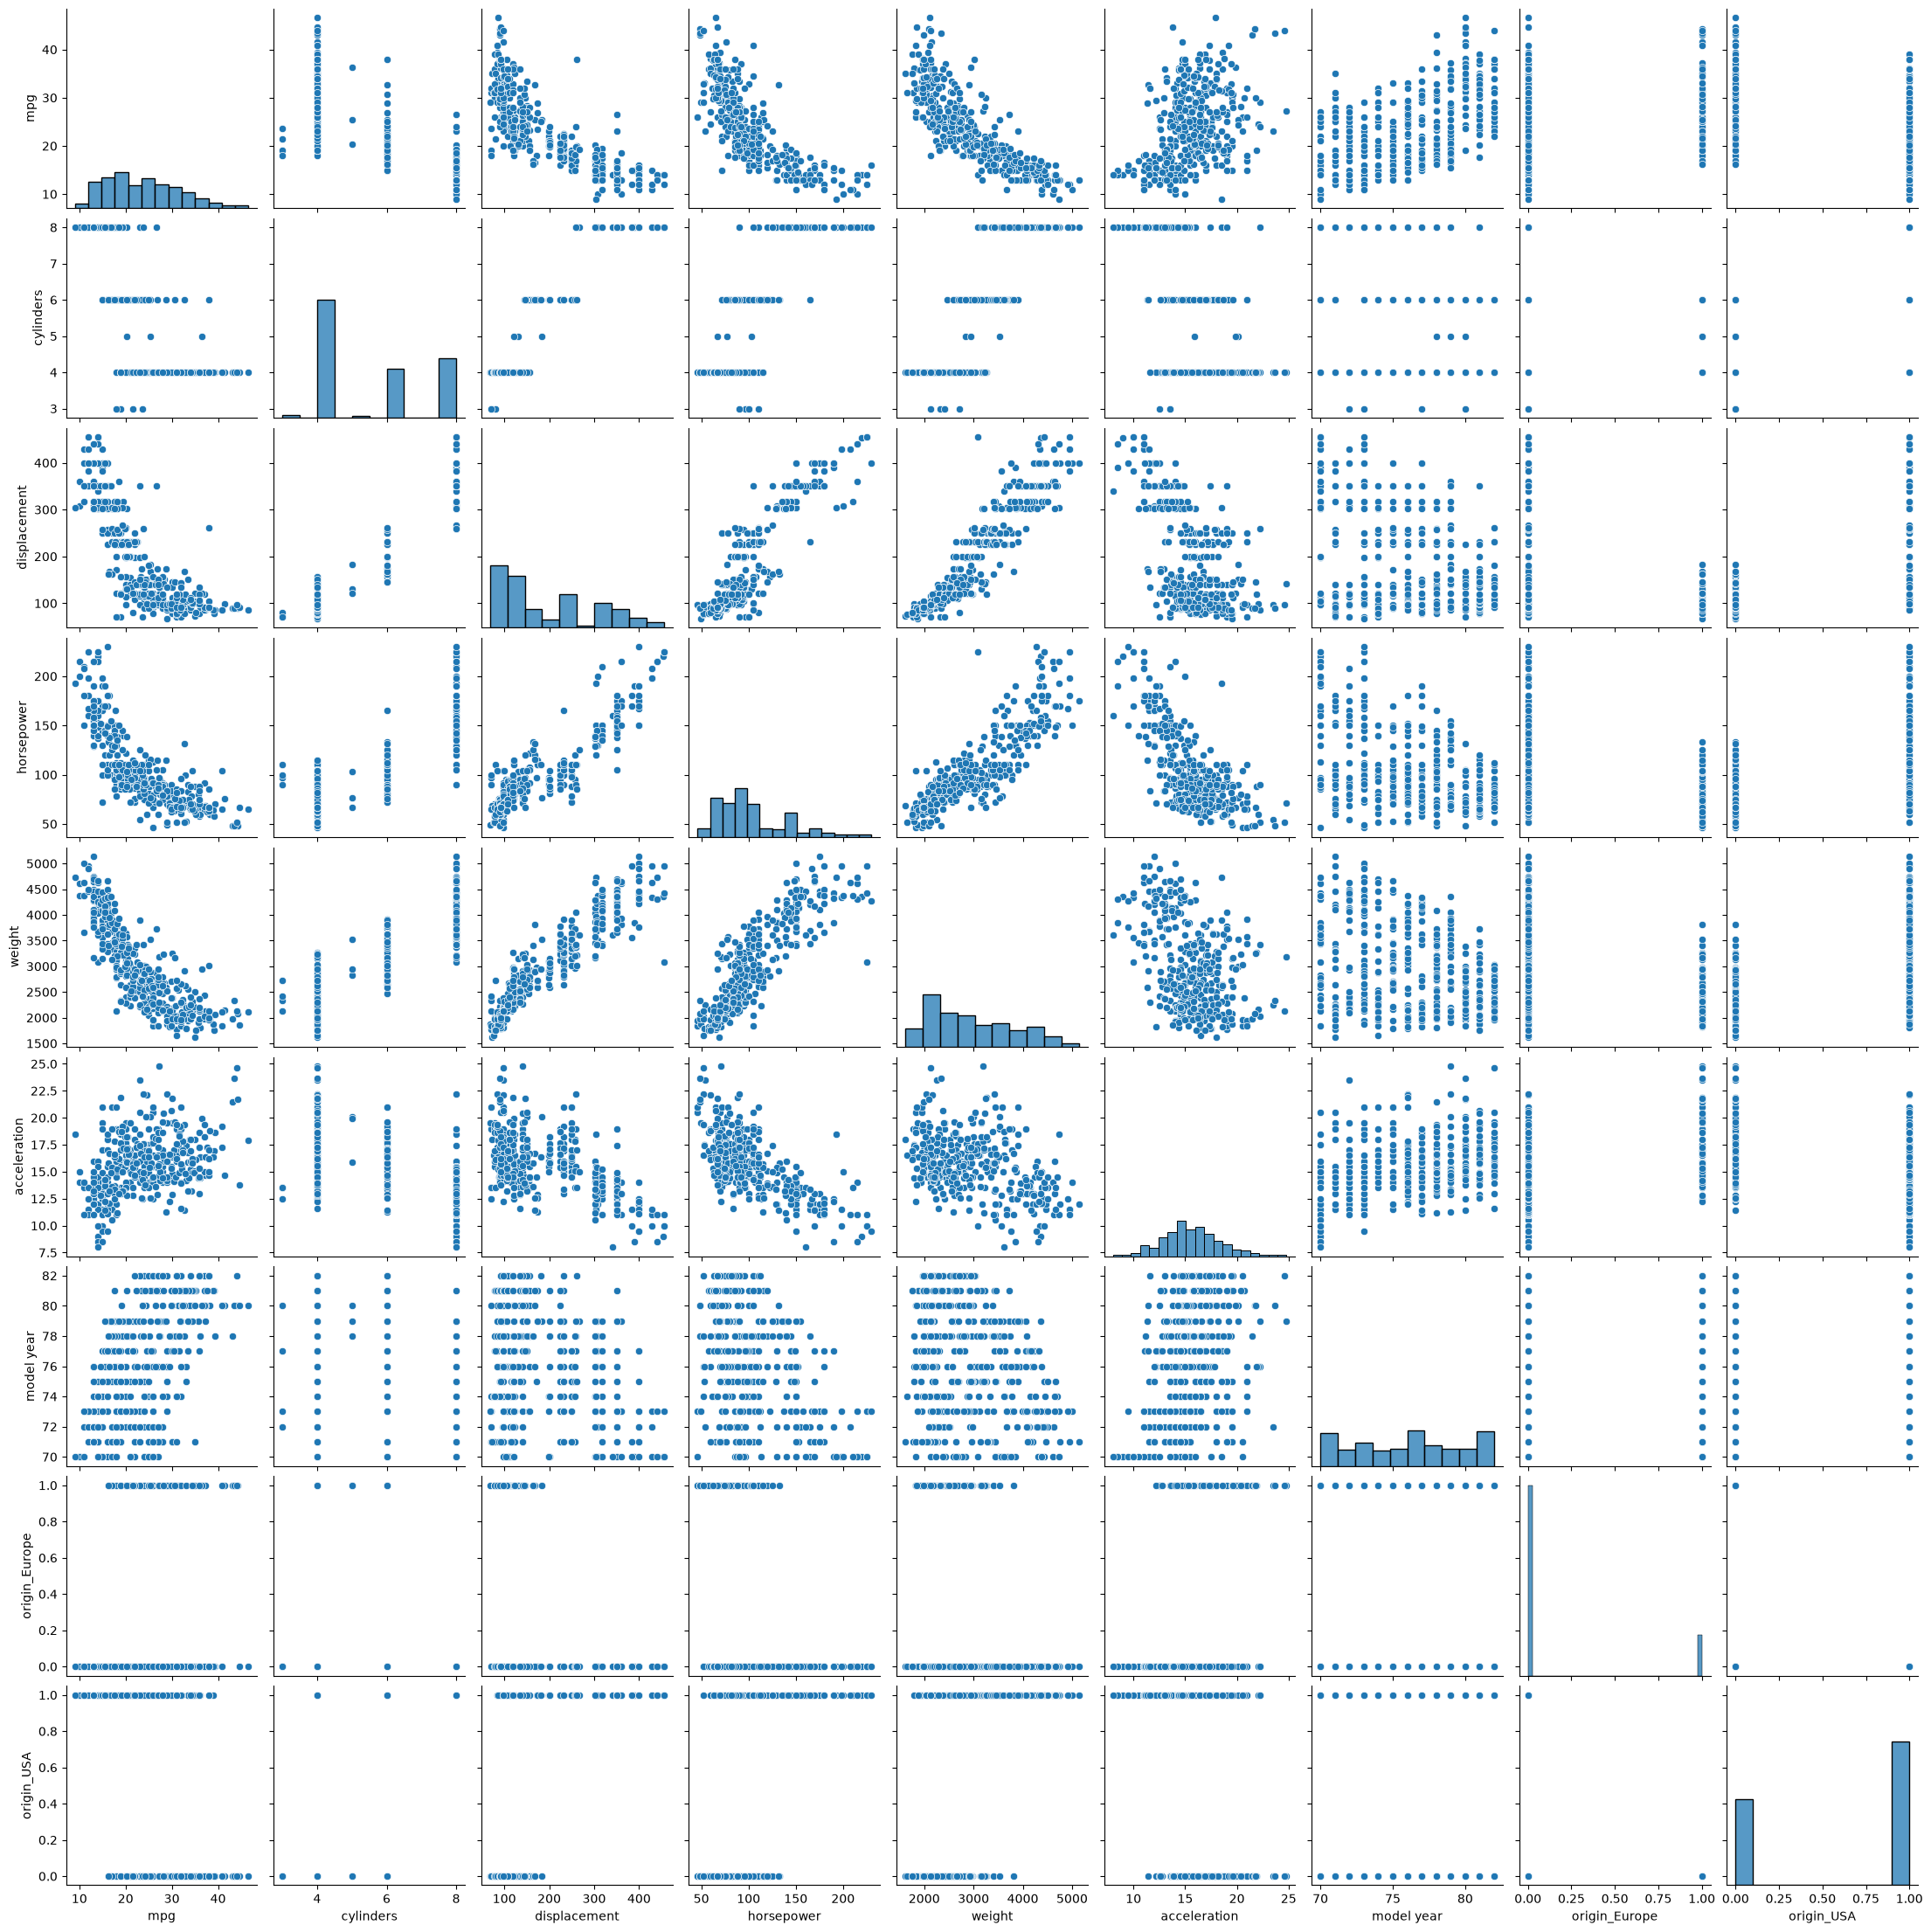

In [129]:
sns.pairplot(df)
#From the pair plot it can seen that mpg has a non linear relationship with most of the independent features

<Axes: >

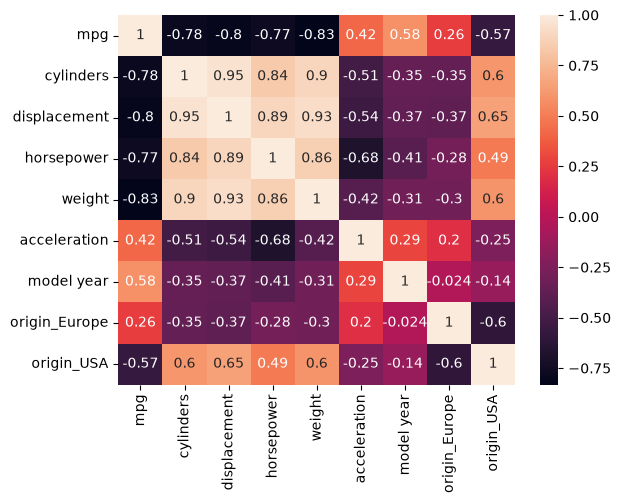

In [130]:
sns.heatmap(corr,annot=True)

In [131]:
#Separate Independent and Dependent Features
X = df.drop(columns=['mpg'])
y = df['mpg']

In [132]:
#Split Train and test data

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42)

### First Use Multiple Linear Regression to check the Prediction Accuracy

In [133]:
#Standardization  -  for Linear Regression

from sklearn.preprocessing import StandardScaler

scaler =  StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

In [134]:
X_test_std

array([[-8.65642818e-01, -1.00213916e+00, -1.37669957e+00,
        -1.42147414e+00,  6.29729008e-01, -2.16101572e-02,
        -4.65109160e-01, -1.28868704e+00],
       [-8.65642818e-01, -7.16705463e-01, -6.64132196e-01,
        -4.24752967e-01,  1.06345608e+00,  1.65834467e+00,
        -4.65109160e-01,  7.75983594e-01],
       [ 3.28623662e-01,  3.85659178e-01, -8.85970060e-02,
        -4.13945147e-01, -9.60603572e-01, -1.42157251e+00,
        -4.65109160e-01,  7.75983594e-01],
       [ 1.52289014e+00,  1.23211774e+00,  1.28172487e+00,
         1.15438962e+00, -8.88315728e-01, -2.16101572e-02,
        -4.65109160e-01,  7.75983594e-01],
       [ 1.52289014e+00,  1.23211774e+00,  1.28172487e+00,
         1.51104768e+00, -4.18444738e-01, -8.61587570e-01,
        -4.65109160e-01,  7.75983594e-01],
       [-8.65642818e-01, -9.43083916e-01, -4.17474257e-01,
        -1.05520913e+00,  3.04433708e-01, -1.14158004e+00,
        -4.65109160e-01, -1.28868704e+00],
       [-8.65642818e-01, -5.198546

In [135]:
# Apply Linear Regression

from sklearn.linear_model import LinearRegression

regression = LinearRegression()

regression.fit(X_train_std,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-0.2 , 1.63,-0.37,..., 2.92, 0.04,-1.39]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,23.53
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[37.71,18.9 ,14.96,..., 6.4 , 4.48, 3.16]"


In [136]:
y_pred = regression.predict(X_test_std)
y_pred

array([32.55855982, 29.18526285, 21.02866991, 16.79422841, 12.40876826,
       26.86557725, 27.55121282, 10.00505847, 16.72800763, 21.58631373,
       12.88142569, 35.96036212, 24.57403126, 13.57557698, 23.4525079 ,
        6.34474838, 29.14798656, 24.93502109, 16.53066906, 36.12287316,
       24.76792769, 18.55150138, 28.64958744, 28.2660852 , 14.815953  ,
       35.93784099, 26.56281267, 24.5090338 , 21.80288449,  8.79937293,
       28.06328038, 36.13067681, 20.62142382, 25.74955146, 34.00756322,
       12.22788158, 22.54911009, 21.80474953, 12.25184788, 27.84639326,
       26.00590633, 28.45452241, 21.22681934,  7.33477913, 24.19720279,
       34.83311345, 27.83192861, 25.36543835, 23.56141631, 28.63005175,
       22.11077751, 33.39693614, 32.46087633, 11.06915371, 27.4954235 ,
       10.03715567, 19.90212389, 29.70176937, 22.63682767, 20.1514161 ,
       16.26888745, 31.74951782, 23.52241402, 21.54794918, 20.55513481,
       25.1562096 , 24.69488485, 31.94722339, 27.56633952, 12.53

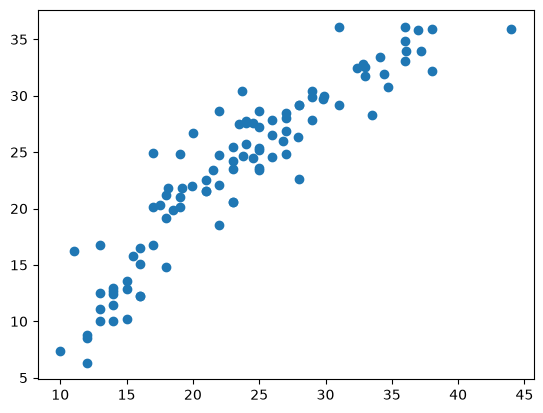

In [137]:
plt.scatter(y_test,y_pred)

In [ ]:
#Performance Metrices

from sklearn.metrics import mean_absolute_error,mean_squared_error

mse = mean_squared_error(y_test,y_pred)
mae =mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mse)

In [139]:
print(mse)
print(mae)
print(rmse)

8.916002022808902
2.3439234136013196
2.9859675187129717


In [140]:
from sklearn.metrics import r2_score

score = r2_score(y_test,y_pred)

print(score)

0.8429825651724543


In [141]:
# adjusted r2 score
print(1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test_std.shape[1]-1))

0.8291788346381646


In [142]:
print("Coefficents are:",regression.coef_)
print("Intercept is:",regression.intercept_)

Coefficents are: [-0.20274998  1.62755014 -0.37173643 -5.71402374  0.22028173  2.91794933
  0.03686325 -1.39259215]
Intercept is: 23.52684563758389


## Observation

### From the r2 Score and Adjusted r2 score it can be seen that the accuracy of the model is not good

### Now Lets apply Polynomial Regression with different degrees to check the accuracy of the Prediction

In [143]:
from sklearn.preprocessing import StandardScaler,PolynomialFeatures

from sklearn.linear_model import LinearRegression

from sklearn.pipeline import Pipeline

In [ ]:
#creating generalized pipeline for n degree polynomial regression

def createPipeline(deg):
    poly_pipeline = Pipeline([
        ('poly',PolynomialFeatures(degree=deg,include_bias=False)),
        ('scaler',StandardScaler()),
        ('poly_reg',LinearRegression())
    ])

    return poly_pipeline

In [145]:
# First doing the prediction using polynomial regression with degree 2

poly_reg1 = createPipeline(2)

poly_reg1.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['cylinders','displacement','horsepower',...,'model year','origin_Europe', 'origin_USA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [146]:
y_pred1 = poly_reg1.predict(X_test)
y_pred1


array([32.28433743, 30.08384052, 20.0499038 , 15.1946266 , 13.54127238,
       26.42557858, 27.37966486, 12.14825609, 17.10671101, 20.2492461 ,
       15.79223207, 37.77761982, 25.3297772 , 15.0277392 , 22.38630483,
       14.00651244, 30.38331663, 18.90320855, 16.94476094, 40.43341388,
       22.36992551, 20.46089808, 29.60553774, 29.76981467, 15.12614863,
       49.02420795, 25.36769086, 23.03445528, 20.10382994, 13.56810214,
       28.74016018, 39.58960101, 19.33958094, 24.3175486 , 34.98254856,
       13.26714903, 24.83235775, 18.42721522, 13.50928796, 26.64738328,
       25.78667142, 26.66903627, 19.28887026,  8.61721772, 22.58145134,
       36.45239132, 25.59423248, 22.0108135 , 22.20482309, 28.54660741,
       19.93335195, 33.16660007, 32.73344916, 11.79428362, 27.34968527,
       13.36744873, 18.65566846, 27.54976938, 23.17739005, 19.01042675,
       15.0272462 , 31.22812063, 22.01352129, 19.7828046 , 20.26072933,
       24.71627148, 22.36171297, 34.84383977, 27.20525468, 14.68

Text(0, 0.5, 'Predicted Mpg')

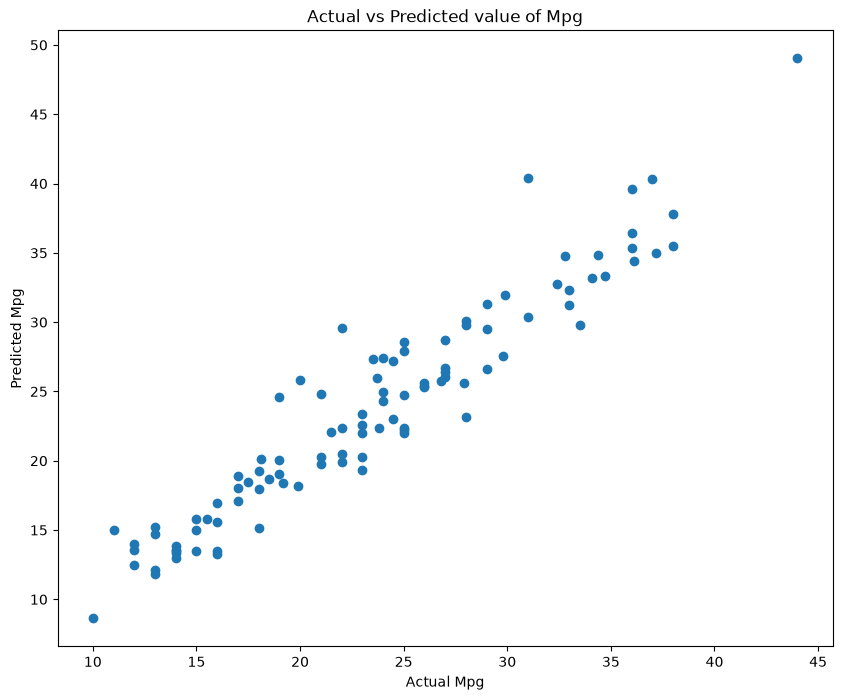

In [147]:
plt.figure(figsize=(10,8))
plt.scatter(y_test,y_pred1)
plt.title("Actual vs Predicted value of Mpg")
plt.xlabel("Actual Mpg")
plt.ylabel("Predicted Mpg")

In [ ]:
#Perfomance Metrices

from sklearn.metrics import mean_absolute_error,mean_squared_error

mse2 = mean_squared_error(y_test,y_pred1)
mae2 = mean_absolute_error(y_test,y_pred1)
rmse2 = np.sqrt(mse2)

In [149]:
print(mse2)
print(mae2)
print(rmse2)

5.776018466608016
1.7826327233163584
2.4033348636026597


In [150]:
from sklearn.metrics import r2_score

score1 = r2_score(y_test,y_pred1)
print(score1)

0.8982800137524416


## Observation

### model accuracy slightly increased, when we used polynomial regression of degree 2

### Apply Polynomial Regression with degree 3


In [152]:
# Second -  doing the prediction using polynomial regression with degree 3

poly_reg2 = createPipeline(3)

poly_reg2.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['cylinders','displacement','horsepower',...,'model year','origin_Europe', 'origin_USA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [153]:
y_pred2 = poly_reg2.predict(X_test)
y_pred2

array([ 27.60007763,  29.06104669,  21.7837695 ,  16.13921049,
        13.06494332,  24.67977705,  24.71088138,  10.1628318 ,
        14.03874344,  17.24123665,  14.08410998,  37.70695392,
        18.96839682,  13.97367788,  23.06854582,  11.80021462,
        29.42263136, -30.25219571,  15.98729062,  34.28043104,
        23.75271726,  19.97049257,  33.91729409,  30.09201713,
        19.80250435,  76.39573594,  25.97954062,  24.61355749,
        23.08725598,  13.93755989,  25.61069359,  36.26339546,
        16.33243677,  23.45761892,  40.36980894,  -2.98614026,
        18.41515813,  22.20599478,  14.00507205,  25.96668248,
        28.38142129,  26.82964781,  17.71723015,  23.71033501,
        22.09019396,  36.73563898,  27.58837792,  18.94233897,
        31.80803488,  28.11045252,  18.48375394,  42.28811913,
        30.99402909,  12.23524418,  29.43975819,  14.3540424 ,
        19.20439917,  28.3184458 ,  23.71164989,  19.35532862,
        12.24358045,  24.93129142,  23.53673629,  21.07

Text(0, 0.5, 'Predicted Mpg')

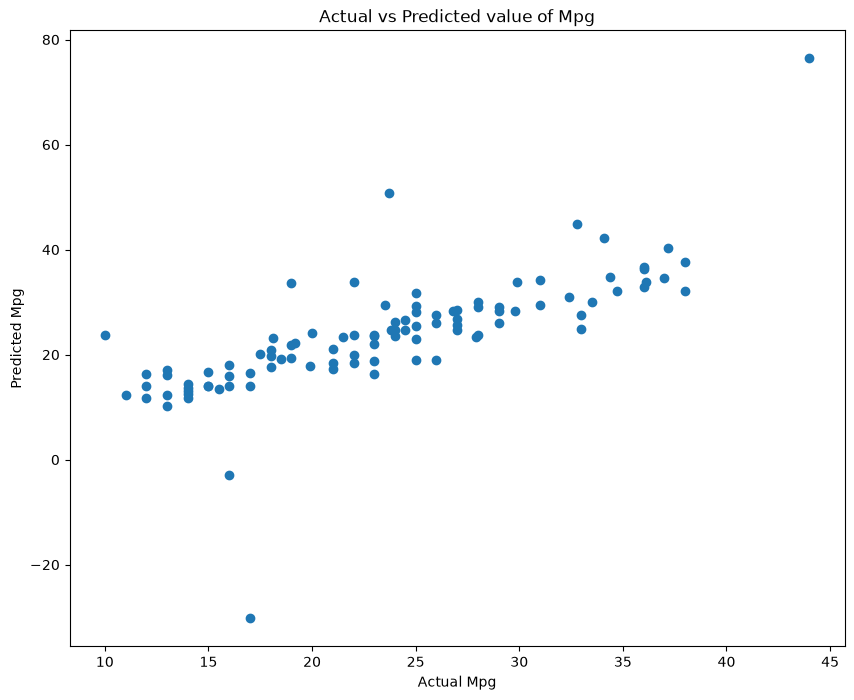

In [154]:
plt.figure(figsize=(10,8))
plt.scatter(y_test,y_pred2)
plt.title("Actual vs Predicted value of Mpg")
plt.xlabel("Actual Mpg")
plt.ylabel("Predicted Mpg")

In [ ]:
#Perfomance Metrices

from sklearn.metrics import mean_absolute_error,mean_squared_error

mse3 = mean_squared_error(y_test,y_pred2)
mae3 = mean_absolute_error(y_test,y_pred2)
rmse3 = np.sqrt(mse3)

In [156]:
print(mse3)
print(mae3)
print(rmse3)

59.089914371271234
3.9348930710540584
7.686996446680019


In [157]:
from sklearn.metrics import r2_score

score2 = r2_score(y_test,y_pred2)
print(score2)

-0.04061739275305243


## Observation

### After applying polynomial regression of degree 3 the score decreased drastically  due to overfitting, so we should take degree 2 for further analysis

### Perform Regularization using Ridge,Lasso and ElasticNet

In [162]:
from sklearn.linear_model import RidgeCV

ridge_pipeline = Pipeline([
    ('poly',PolynomialFeatures(degree=2,include_bias=False)),
    ('scaler',StandardScaler()),
    ('ridge',RidgeCV(alphas=np.logspace(-3,3,50),cv=5))
])

ridge_pipeline.fit(X_train,y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['cylinders','displacement','horsepower',...,'model year','origin_Europe', 'origin_USA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [164]:
y_pred_ridge = ridge_pipeline.predict(X_test)
y_pred_ridge

array([34.20488539, 29.9287597 , 19.54574802, 16.15800102, 13.27502821,
       25.69729249, 27.75913173, 13.16732768, 16.95545428, 20.13662182,
       14.17906777, 37.47238513, 24.87355324, 14.23609013, 23.20448678,
       11.84558684, 30.63072957, 20.93463802, 16.02654827, 37.99576048,
       23.89689701, 18.04105658, 26.3510187 , 29.60704355, 14.75206116,
       41.81832022, 25.45589815, 24.1065679 , 19.76557089, 12.64491429,
       28.76260271, 36.9724747 , 18.01398396, 23.7838071 , 35.63586559,
       13.8906023 , 22.54938173, 19.22431602, 13.70748171, 27.3622921 ,
       25.69810703, 29.18124557, 18.9431709 ,  9.91770574, 22.17625623,
       33.92151632, 26.45401368, 22.61307012, 22.15024943, 29.22469173,
       20.99044593, 34.67357779, 32.925764  , 12.48903517, 27.48475279,
       12.71021615, 17.94697429, 28.25599946, 21.97815579, 19.32767951,
       15.06316796, 33.23644638, 23.11442182, 20.83441143, 19.84499085,
       23.14119672, 23.98285138, 34.61974616, 28.32352374, 13.78

Text(0, 0.5, 'Predicted Mpg')

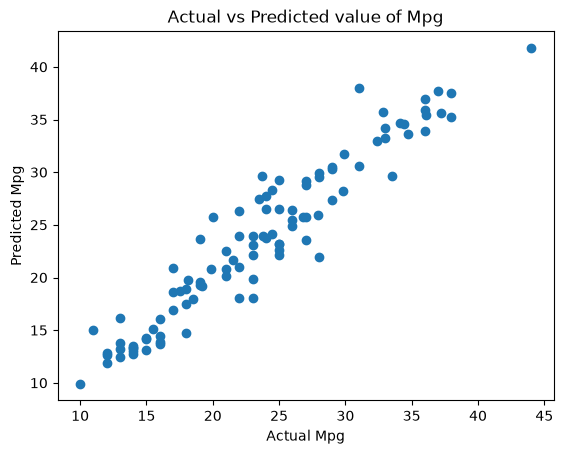

In [200]:
plt.scatter(y_test,y_pred_ridge)
plt.title("Actual vs Predicted value of Mpg")
plt.xlabel("Actual Mpg")
plt.ylabel("Predicted Mpg")

In [166]:
mse_ridge = mean_squared_error(y_test,y_pred_ridge)
mae_ridge = mean_absolute_error(y_test,y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)

In [181]:
print("Mean Squared error:",mse_ridge)
print("Mean absolute error",mae_ridge)
print("Root Mean Squared error",rmse_ridge)

Mean Squared error: 5.247635914847043
Mean absolute error 1.7027312004376025
Root Mean Squared error 2.2907719037143446


In [183]:
score_ridge = r2_score(y_test,y_pred_ridge)
print("Test R2 Score:",score_ridge)

Test R2 Score: 0.907585223943388


In [171]:
alpha = ridge_pipeline.named_steps['ridge'].alpha_
print("Optimal Alpha Value from Cross Validation is:",alpha)

Optimal Alpha Value from Cross Validation is: 1.5264179671752334


## Observation

### After applying ridge or L2 regularization the model performance increased slightly due to the reduction of Overfitting

### Apply Lasso or L1 Regularization for feature selection

In [172]:
from sklearn.linear_model import LassoCV

In [173]:
lasso_pipeline = Pipeline([
    ('poly',PolynomialFeatures(degree=2,include_bias=False)),
    ('scaler',StandardScaler()),
    ('lasso',LassoCV(cv=5,max_iter=10000,random_state=42))
])

In [174]:
lasso_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['cylinders','displacement','horsepower',...,'model year','origin_Europe', 'origin_USA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [175]:
y_pred_lasso = lasso_pipeline.predict(X_test)
print(y_pred_lasso)

[34.0409164  29.99757355 19.59795379 16.19437669 13.20988918 25.83384828
 27.68535038 12.78273694 16.55499425 20.07788234 14.19965611 37.66923677
 24.87807143 14.20379203 23.17026854 11.77442693 30.41343372 21.88194716
 16.04212093 38.20714334 24.16339892 17.84776531 26.92805785 29.53440687
 14.90761385 40.65907064 25.51094347 24.04627113 19.857549   12.64321018
 28.51918251 37.3110234  18.00698842 23.96771493 35.60683957 13.71924086
 22.39641865 19.71906939 13.58355926 27.3575725  25.89474976 29.3373872
 18.9502587   9.6510335  22.24028982 34.46785424 26.81430536 22.63805371
 22.22670468 29.08854607 21.32797425 34.62969423 32.89818309 12.34259652
 27.72128563 12.60390945 18.13740359 28.26707329 21.97162433 19.19714248
 15.33410321 33.04768403 23.11850065 21.04144427 19.66541663 23.25135666
 24.11974401 34.53012657 28.48128599 13.75133603 33.16595004 13.3625869
 12.76505749 17.49865194 26.5676183  20.84303454 18.72671067 29.77061504
 30.58279878 18.60380544 14.66573513 23.58925071 37.8

Text(0, 0.5, 'Predicted Mpg')

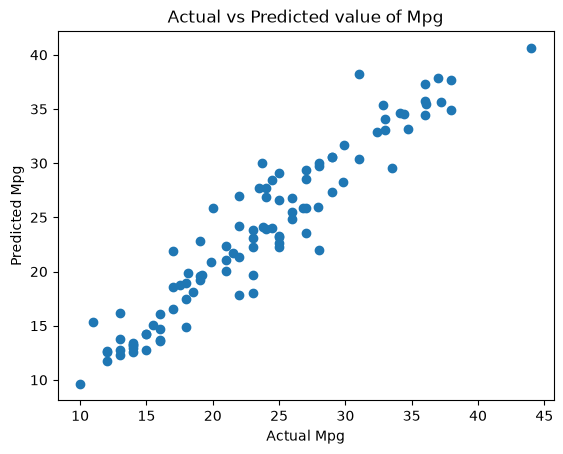

In [201]:
plt.scatter(y_test,y_pred_lasso)
plt.title("Actual vs Predicted value of Mpg")
plt.xlabel("Actual Mpg")
plt.ylabel("Predicted Mpg")

In [179]:
mse_lasso = mean_squared_error(y_test,y_pred_lasso)
mae_lasso = mean_absolute_error(y_test,y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)

In [180]:
print("Mean Squared error:",mse_lasso)
print("Mean absolute error",mae_lasso)
print("Root Mean Squared error",rmse_lasso)

Mean Squared error: 5.603009516713752
Mean absolute error 1.7623280026305
Root Mean Squared error 2.36706770429444


In [182]:
score_lasso = r2_score(y_test,y_pred_lasso)
print("Test R2 Score:",score_lasso)

Test R2 Score: 0.9013268301893502


In [184]:
alpha_lasso = lasso_pipeline.named_steps['lasso'].alpha_
print("Optimal Alpha Value:",alpha_lasso)

Optimal Alpha Value: 0.017296489188724805


In [186]:
poly_step = lasso_pipeline.named_steps['poly']
lasso_step = lasso_pipeline.named_steps['lasso']

poly_features = poly_step.get_feature_names_out(X.columns)
active_features = poly_features[lasso_step.coef_ != 0]


In [187]:
print("Total features in Degree-2 polynomial regression:",len(poly_features))
print("Total Active Features in Lasso:",len(active_features))

Total features in Degree-2 polynomial regression: 44
Total Active Features in Lasso: 16


## Observation

### With the Help of Lasso we were able to select the active features and improve the R2 Score

### Apply ElasticNet Regression -  Combination of Both L1 and L2 Regularization

In [188]:
from sklearn.linear_model import ElasticNetCV

In [190]:
Elastic_pipeline = Pipeline([
    ('poly',PolynomialFeatures(degree=2,include_bias=False)),
    ('scaler',StandardScaler()),
    ('Elasticnet',ElasticNetCV(l1_ratio=[0.1,0.5,0.7,0.9,0.95,0.99],cv=5,max_iter=10000,random_state=42))
])

In [191]:
Elastic_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['cylinders','displacement','horsepower',...,'model year','origin_Europe', 'origin_USA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [192]:
y_pred_elastic = Elastic_pipeline.predict(X_test)
print(y_pred_elastic)

[34.03225701 30.042465   19.5648069  16.21234754 13.19317582 25.803732
 27.74058513 12.83339863 16.52586822 20.08156605 14.17358296 37.63387135
 24.83064028 14.24173384 23.20836309 11.64525263 30.47772004 21.79229424
 15.99623202 38.1441761  24.22002029 17.90219286 26.79351546 29.45660992
 14.96655783 40.65859238 25.51044416 24.07628905 19.83832867 12.51461958
 28.6162188  37.14954915 17.95834814 23.93599696 35.63207826 13.80726005
 22.3798941  19.66990066 13.52674606 27.36517058 25.82081867 29.29549512
 19.02336727  9.84366451 22.25224546 34.29283132 26.80710535 22.61230596
 22.2996056  29.14911914 21.28720895 34.64832879 32.94318374 12.37171159
 27.67447307 12.58936282 18.11570146 28.32124031 21.90314014 19.26847619
 15.30257308 33.04190848 23.14238638 21.12175629 19.72111344 23.19911178
 24.1487352  34.5454551  28.43207116 13.76837967 33.31413416 13.33963613
 12.81234576 17.47520042 26.56905245 20.94396149 18.72940347 29.75647825
 30.50639539 18.64052863 14.69303936 23.5732234  37.8

Text(0, 0.5, 'Predicted Mpg')

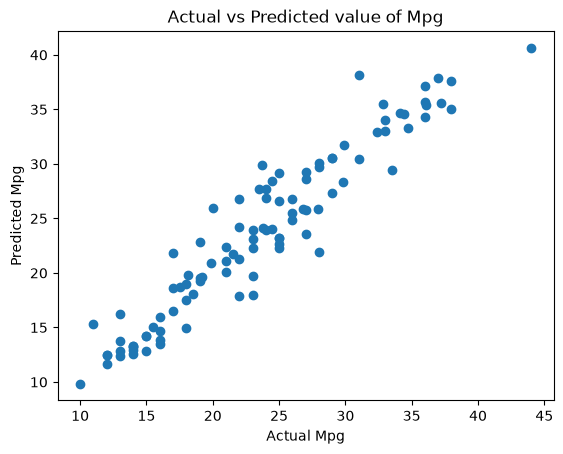

In [202]:
plt.scatter(y_test,y_pred_elastic)
plt.title("Actual vs Predicted value of Mpg")
plt.xlabel("Actual Mpg")
plt.ylabel("Predicted Mpg")

In [194]:
mse_elastic = mean_squared_error(y_test,y_pred_elastic)
mae_elastic = mean_absolute_error(y_test,y_pred_elastic)
rmse_elastic = np.sqrt(mse_elastic)

In [195]:
print("Mean Squared error:",mse_elastic)
print("Mean absolute error",mae_elastic)
print("Root Mean Squared error",rmse_elastic)

Mean Squared error: 5.582042429194282
Mean absolute error 1.7620768288409046
Root Mean Squared error 2.362634637262876


In [196]:
score_elastic = r2_score(y_test,y_pred_elastic)
print("Test R2 Score:",score_elastic)

Test R2 Score: 0.9016960762134862


In [198]:
alpha_elastic = Elastic_pipeline.named_steps['Elasticnet'].alpha_
l1_ratio = Elastic_pipeline.named_steps['Elasticnet'].l1_ratio_

In [ ]:
print("Optimal Alpha value:",alpha_elastic)
print("Optimal L1 ratio:",l1_ratio)

Optimal Alpha value 0.015835372863876495
Optimal L1 ratio: 0.95
